# CatBoost and DummyClassifier

Supplementary baseline extension requested after inspecting the first four models. This is exploratory use of Validation A, not an independent final evaluation. Run after the existing baseline notebooks. Each model has separate configuration, fitting and evaluation cells.

CatBoost uses the same 21 predictors with native categorical handling. DummyClassifier ignores predictors and returns the Late prevalence learned on Train. B/Test are checked for counts only; neither is predicted or used for fitting or selection.

## Environment and repository

In [1]:
from pathlib import Path
from datetime import datetime
import hashlib
import importlib.metadata
import json
import platform
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

current = Path.cwd().resolve()
ROOT = next(
    (p for p in [current, *current.parents]
     if (p / "docs/predictor_list.csv").is_file()
     and (p / "notebooks").is_dir()), None
)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the project repository.")
print("Repository:", ROOT)
print("Python:", platform.python_version())


Repository: C:\Users\LENOVO\OneDrive\Desktop\PTTK
Python: 3.14.6


## Libraries and inputs

Use the same dataset, predictors and split manifest as Logistic Regression / Random Forest.

In [2]:
from catboost import CatBoostClassifier

from sklearn.dummy import DummyClassifier

from sklearn.compose import ColumnTransformer

from sklearn.impute import SimpleImputer

from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, precision_recall_curve, roc_auc_score

from sklearn.pipeline import Pipeline



INPUTS = ['data/processed/research_data_weather_price_holiday_assume_utc.csv', 'docs/predictor_list.csv', 'data/ml_preparation/split_manifest.csv']

EXPECTED = {'train': (57449, 3720), 'validation_a': (7661, 387), 'validation_b': (3115, 180), 'test': (9445, 504)}


## Load and audit splits

Check unique order IDs, valid labels and the expected sample sizes. B/Test are not used for model selection.

In [3]:
features = pd.read_csv(ROOT / INPUTS[1]).feature.tolist()

assert len(features) == len(set(features)) == 21

df = pd.read_csv(ROOT / INPUTS[0])

manifest = pd.read_csv(ROOT / INPUTS[2])

assert df.order_id.is_unique and manifest.order_id.is_unique

selected = manifest.loc[manifest.split.isin(EXPECTED), ['order_id', 'split']]

data = selected.merge(df, on='order_id', how='left', validate='one_to_one', indicator=True)

assert data._merge.eq('both').all()

audit = []

for split, (n, positives) in EXPECTED.items():
    z = data.loc[data.split.eq(split)]
    assert len(z) == n and z.is_late.notna().all()
    assert z.is_late.isin([0, 1]).all() and int(z.is_late.sum()) == positives
    audit.append(dict(split=split, n=n, late=positives))
display(pd.DataFrame(audit))


,split,n,late
0,train,57449,3720
1,validation_a,7661,387
2,validation_b,3115,180
3,test,9445,504


## Prepare features

Imputation and one-hot encoding are fitted on Train only; tree models use no scaling.

In [4]:
train = data.loc[data.split.eq('train')].copy()

val = data.loc[data.split.eq('validation_a')].copy()

cat = ['customer_state', 'purchase_weekday']

num = [f for f in features if f not in cat]

for z in (train, val):
    for c in cat:
        z[c] = z[c].map(lambda v: str(v) if pd.notna(v) else np.nan)
    for c in num:
        z[c] = pd.to_numeric(z[c], errors='raise').replace([np.inf, -np.inf], np.nan)

assert not train[features].isna().all().any()

hashes = {p: hashlib.sha256((ROOT / p).read_bytes()).hexdigest() for p in INPUTS}

lf_hashes = {p: hashlib.sha256((ROOT / p).read_bytes().replace(b'\r\n', b'\n')).hexdigest() for p in INPUTS}


## Predeclared configurations

Fixed before running these two additional baselines. No tuning, weighting, early stopping, calibration or threshold selection.

In [5]:
catboost_classifier = CatBoostClassifier(
    iterations=100, learning_rate=0.1, depth=6,
    loss_function="Logloss", eval_metric="Logloss",
    random_seed=42, thread_count=4, task_type="CPU",
    use_best_model=False, allow_writing_files=False, verbose=False,
    cat_features=cat,
)
dummy_classifier = DummyClassifier(strategy="prior", random_state=42)
y_train = train.is_late.astype(int)
y_validation = val.is_late.astype(int)


## Create run folders and save provenance

The experiment plan is written before either model is fitted. Numeric medians are fitted on Train; categorical missing values use a fixed string.

In [6]:
run = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
tables = ROOT / "outputs/tables/machine_learning/ml_catboost_dummy" / run
figures = ROOT / "outputs/figures/ml_catboost_dummy" / run
saved = ROOT / "outputs/models/ml_catboost_dummy" / run
for path in [tables, figures, saved]:
    path.mkdir(parents=True, exist_ok=False)
pd.DataFrame(audit).to_csv(tables / "input_audit.csv", index=False)
pd.DataFrame({
    "feature": features,
    "missing_train": train[features].isna().sum().to_numpy(),
    "unique_train": train[features].nunique().to_numpy(),
}).to_csv(tables / "feature_audit.csv", index=False)
for filename, values in [("input_hashes.json", hashes), ("input_lf_hashes.json", lf_hashes)]:
    (tables / filename).write_text(json.dumps(values, indent=2), encoding="utf-8")
versions = {name: importlib.metadata.version(name) for name in [
    "numpy", "pandas", "scipy", "scikit-learn", "joblib", "matplotlib", "catboost",
]}
versions["python"] = platform.python_version()
(tables / "package_versions.json").write_text(json.dumps(versions, indent=2), encoding="utf-8")
plan = {
    "purpose": "supplementary exploratory baseline comparison on Validation A",
    "CatBoost": catboost_classifier.get_params(),
    "DummyClassifier": dummy_classifier.get_params(),
    "fit_split": "train", "score_split": "validation_a",
    "tuning": False, "weighting": "none", "early_stopping": False,
    "calibration": False, "threshold_selection": False,
    "preprocessing": "CatBoost: train median + categorical missing string, native categorical handling; Dummy: no feature learning",
}
(tables / "experiment_plan.json").write_text(json.dumps(plan, indent=2), encoding="utf-8")
print("Run:", run)


Run: 20261111_152855_922857


## CatBoost: fit Train

No eval_set is passed, so Validation A cannot influence fitting or stopping. Both categorical columns retain their original information rather than being one-hot encoded.

In [7]:
catboost_preprocessor = ColumnTransformer(
    [
        ("numeric", SimpleImputer(strategy="median"), num),
        ("category", SimpleImputer(strategy="constant", fill_value="__MISSING__"), cat),
    ],
    verbose_feature_names_out=False,
).set_output(transform="pandas")
catboost_pipeline = Pipeline([
    ("preprocessing", catboost_preprocessor),
    ("classifier", catboost_classifier),
])
start = time.perf_counter()
catboost_pipeline.fit(train[features], y_train)
catboost_training_seconds = time.perf_counter() - start
print("CatBoost training seconds:", round(catboost_training_seconds, 3))


CatBoost training seconds: 11.401


## CatBoost: evaluate Validation A and save pipeline

Report the same four metrics as the previous baselines and verify model reload.

In [8]:
catboost_probabilities = catboost_pipeline.predict_proba(val[features])[:, 1]
assert np.isfinite(catboost_probabilities).all()
assert ((catboost_probabilities >= 0) & (catboost_probabilities <= 1)).all()
joblib.dump(catboost_pipeline, saved / "CatBoost.joblib")
np.testing.assert_allclose(
    joblib.load(saved / "CatBoost.joblib").predict_proba(val[features])[:, 1],
    catboost_probabilities,
)
catboost_metrics = dict(
    model="CatBoost", split="validation_a", probability_type="raw",
    n=len(y_validation), late=int(y_validation.sum()), prevalence=float(y_validation.mean()),
    AP=average_precision_score(y_validation, catboost_probabilities),
    ROC_AUC=roc_auc_score(y_validation, catboost_probabilities),
    Brier=brier_score_loss(y_validation, catboost_probabilities),
    LogLoss=log_loss(y_validation, catboost_probabilities, labels=[0, 1]),
)
catboost_predictions = pd.DataFrame(dict(
    order_id=val.order_id.to_numpy(), split="validation_a", model="CatBoost",
    y_true=y_validation.to_numpy(), probability=catboost_probabilities,
    prediction=np.nan, threshold=np.nan, probability_type="raw",
))
display(pd.DataFrame([catboost_metrics]))


,model,split,probability_type,n,late,prevalence,AP,ROC_AUC,Brier,LogLoss
0,CatBoost,validation_a,raw,7661,387,0.050516,0.092855,0.655757,0.047227,0.192596


## DummyClassifier: fit Train

A constant-probability reference. It learns only the class proportions on Train; it does not learn from Validation A prevalence.

In [9]:
dummy_pipeline = Pipeline([("classifier", dummy_classifier)])
start = time.perf_counter()
dummy_pipeline.fit(train[features], y_train)
dummy_training_seconds = time.perf_counter() - start
print("Training Late prevalence:", float(y_train.mean()))


Training Late prevalence: 0.06475308534526275


## DummyClassifier: evaluate Validation A and save reference

AP should equal Validation A prevalence for tied predictions; ROC-AUC should equal 0.5. These are diagnostic checks for the reference, not performance targets for learned models.

In [10]:
dummy_probabilities = dummy_pipeline.predict_proba(val[features])[:, 1]
assert np.isfinite(dummy_probabilities).all()
assert ((dummy_probabilities >= 0) & (dummy_probabilities <= 1)).all()
joblib.dump(dummy_pipeline, saved / "DummyClassifier.joblib")
np.testing.assert_allclose(
    joblib.load(saved / "DummyClassifier.joblib").predict_proba(val[features])[:, 1],
    dummy_probabilities,
)
dummy_metrics = dict(
    model="DummyClassifier", split="validation_a", probability_type="raw",
    n=len(y_validation), late=int(y_validation.sum()), prevalence=float(y_validation.mean()),
    AP=average_precision_score(y_validation, dummy_probabilities),
    ROC_AUC=roc_auc_score(y_validation, dummy_probabilities),
    Brier=brier_score_loss(y_validation, dummy_probabilities),
    LogLoss=log_loss(y_validation, dummy_probabilities, labels=[0, 1]),
)
dummy_predictions = pd.DataFrame(dict(
    order_id=val.order_id.to_numpy(), split="validation_a", model="DummyClassifier",
    y_true=y_validation.to_numpy(), probability=dummy_probabilities,
    prediction=np.nan, threshold=np.nan, probability_type="raw",
))
display(pd.DataFrame([dummy_metrics]))

np.testing.assert_allclose(dummy_probabilities, float(y_train.mean()))
np.testing.assert_allclose(dummy_metrics["AP"], float(y_validation.mean()))
np.testing.assert_allclose(dummy_metrics["ROC_AUC"], 0.5)


,model,split,probability_type,n,late,prevalence,AP,ROC_AUC,Brier,LogLoss
0,DummyClassifier,validation_a,raw,7661,387,0.050516,0.050516,0.5,0.048166,0.201833


## Export metrics, predictions and experiment logs

Preserve both models as a new run; existing baseline runs remain unchanged.

In [11]:
metrics = pd.DataFrame([catboost_metrics, dummy_metrics])
validation_predictions = pd.concat([catboost_predictions, dummy_predictions], ignore_index=True)
metrics.to_csv(tables / "validation_a_metrics.csv", index=False)
validation_predictions.to_csv(tables / "validation_predictions.csv", index=False)
logs = [
    dict(model="CatBoost", training_seconds=catboost_training_seconds,
         parameters=catboost_classifier.get_params(), fitted_parameters=catboost_classifier.get_all_params()),
    dict(model="DummyClassifier", training_seconds=dummy_training_seconds,
         parameters=dummy_classifier.get_params()),
]
(tables / "experiment_log.json").write_text(json.dumps(logs, indent=2, default=str), encoding="utf-8")


2954

## Compare all six models

Include previous runs only when input hashes and Validation A IDs/labels match. Recompute their metrics from predictions before consolidation.

In [12]:
parts = [metrics]
prediction_parts = [validation_predictions]
comparison_sources = {}
expected_labels = val.set_index("order_id").is_late.astype(int).sort_index()
for folder, expected_models in [
    ("ml_logistic_random_forest", {"LogisticRegression", "RandomForest"}),
    ("ml_lightgbm_xgboost", {"LightGBM", "XGBoost"}),
]:
    for source in sorted((ROOT / "outputs/tables/machine_learning" / folder).glob("*/input_hashes.json"), reverse=True):
        previous_hashes = {k.replace("\\", "/"): v for k, v in json.loads(source.read_text(encoding="utf-8")).items()}
        if previous_hashes != hashes and previous_hashes != lf_hashes:
            continue
        previous_predictions = pd.read_csv(source.parent / "validation_predictions.csv")
        previous_metrics = pd.read_csv(source.parent / "validation_a_metrics.csv")
        assert set(previous_metrics.model) == set(previous_predictions.model) == expected_models
        assert previous_metrics.model.is_unique
        for model_name, group in previous_predictions.groupby("model"):
            assert group.split.eq("validation_a").all()
            observed = group.set_index("order_id").y_true.astype(int).sort_index()
            pd.testing.assert_series_equal(expected_labels, observed, check_names=False)
            calculated = [
                average_precision_score(group.y_true, group.probability),
                roc_auc_score(group.y_true, group.probability),
                brier_score_loss(group.y_true, group.probability),
                log_loss(group.y_true, group.probability, labels=[0, 1]),
            ]
            recorded = previous_metrics.loc[previous_metrics.model.eq(model_name), ["AP", "ROC_AUC", "Brier", "LogLoss"]].iloc[0].to_numpy(dtype=float)
            # Float32 model probabilities may round differently after CSV reload as float64.
            np.testing.assert_allclose(calculated, recorded, rtol=1e-8, atol=1e-10)
        parts.append(previous_metrics)
        prediction_parts.append(previous_predictions)
        comparison_sources[folder] = str(source.parent.relative_to(ROOT))
        break
    else:
        raise FileNotFoundError(f"No matching baseline run in {folder}; run its notebook first.")
comparison = pd.concat(parts, ignore_index=True).sort_values("AP", ascending=False)
assert len(comparison) == 6 and comparison.model.is_unique
assert comparison.n.eq(len(val)).all() and comparison.late.eq(int(y_validation.sum())).all()
comparison.to_csv(tables / "six_model_comparison.csv", index=False)
(tables / "comparison_source.json").write_text(json.dumps(comparison_sources, indent=2), encoding="utf-8")
all_predictions = pd.concat(prediction_parts, ignore_index=True)
display(comparison)


,model,split,probability_type,n,late,prevalence,AP,ROC_AUC,Brier,LogLoss
0,CatBoost,validation_a,raw,7661,387,0.050516,0.092855,0.655757,0.047227,0.192596
2,LogisticRegression,validation_a,raw,7661,387,0.050516,0.091637,0.642369,0.047720,0.196408
5,XGBoost,validation_a,raw,7661,387,0.050516,0.076845,0.596653,0.047978,0.199795
3,RandomForest,validation_a,raw,7661,387,0.050516,0.074766,0.604052,0.048191,0.200893
4,LightGBM,validation_a,raw,7661,387,0.050516,0.073623,0.582513,0.048189,0.201357
1,DummyClassifier,validation_a,raw,7661,387,0.050516,0.050516,0.500000,0.048166,0.201833


## Inspect precision-recall curves

Validation A has been reused for exploratory model selection. These curves do not justify choosing a threshold or making a final Test claim.

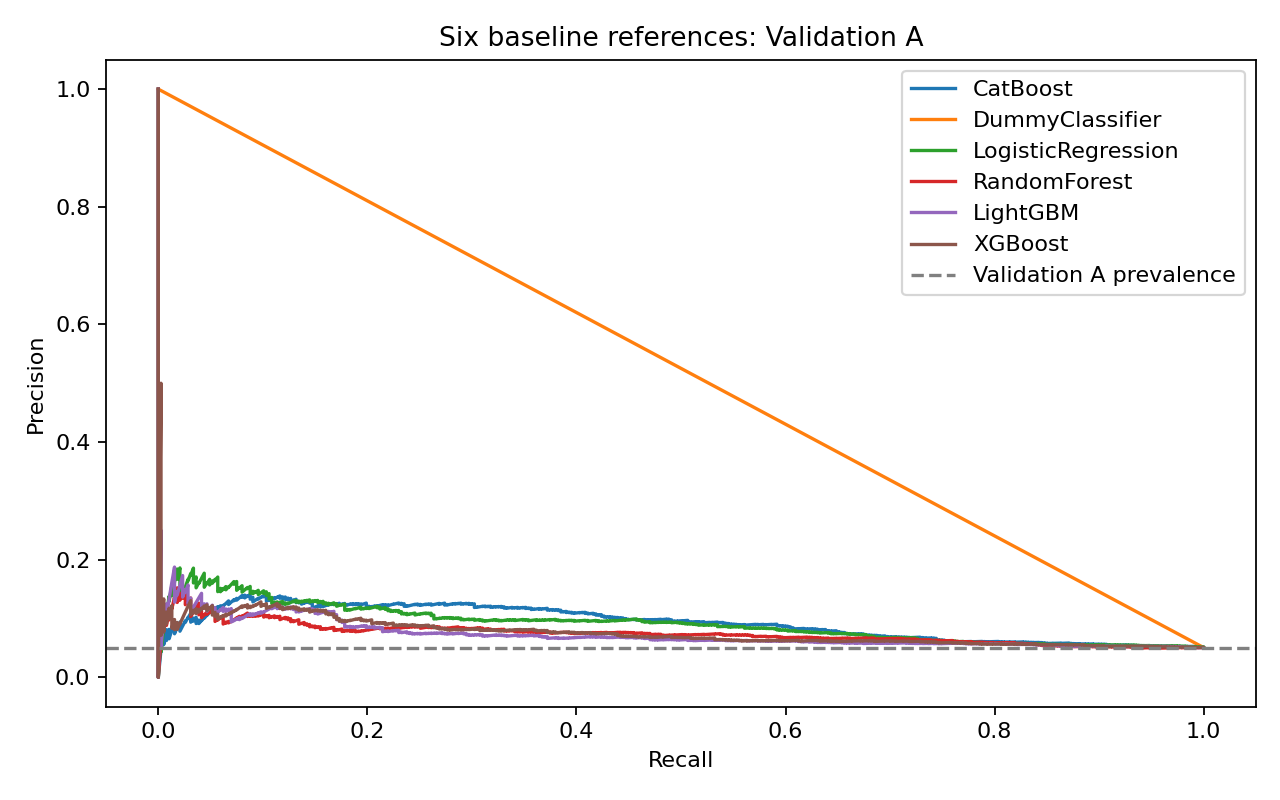

Results: C:\Users\LENOVO\OneDrive\Desktop\PTTK\outputs\tables\ml_catboost_dummy\20261111_152855_922857
B/Test not scored. No weighting, calibration or threshold selected.


In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
for name, group in all_predictions.groupby("model", sort=False):
    precision, recall, _ = precision_recall_curve(group.y_true, group.probability)
    ax.plot(recall, precision, label=name)
ax.axhline(float(y_validation.mean()), color="gray", linestyle="--", label="Validation A prevalence")
ax.set(xlabel="Recall", ylabel="Precision", title="Six baseline references: Validation A")
ax.legend()
fig.tight_layout()
path = figures / "validation_a_pr_curve.png"
fig.savefig(path, dpi=160)
display(Image(filename=str(path)))
plt.close(fig)
print("Results:", tables)
print("B/Test not scored. No weighting, calibration or threshold selected.")
